# 03 · Does listening add anything? (a within-March check)

The listening logs released with the data cover March 2017 only, after the March cutoff, so
they cannot enter notebook 02's out-of-time model. The plan's secondary question: for March
members, does listening in the **14 days before their own expiry date** add to the payment-only
model? Both models are trained on a random half of March and compared on the other half. This
is a within-month result, and the prediction point (each member's expiry) is later than notebook
02's (1 March).

| | |
|---|---|
| **Question** | Does how much a member listens in the 14 days before expiry improve the payment-based model? |
| **Answer** | Barely. Adding listening moves PR-AUC from 0.719 to 0.730 (+0.011). Payment behaviour carries almost all of the signal, so listening data is not worth building a pipeline for this purpose. |
| **Next** | [Notebook 04](04_kkbox_lifetime_value.ipynb) puts a value on each member. |

In [1]:
import os
import sys
from pathlib import Path


def _root() -> Path:
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "data" / "kkbox.py").exists():
            return p
    raise FileNotFoundError("run from inside the project folder")


ROOT = _root()
sys.path.insert(0, str(ROOT))

import lightgbm as lgb
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

from src import records
from src.churn.model import Prep, metrics, paired_bootstrap_pr_auc
from src.data import kkbox

con, SOURCE = kkbox.connect()
BOOT = int(os.environ.get("KKBOX_BOOT", "1000"))
SEED = 20261101
has_logs = "logs" in [r[0] for r in con.execute("SHOW TABLES").fetchall()]
print(f"source: {SOURCE}; listening logs available: {has_logs}")

source: real; listening logs available: True


## 1. Listening features, 14 days before each member's expiry

In [2]:
LISTEN = ["days_active", "total_hours", "unique_songs", "songs_played", "share_completed", "share_skipped",
          "hours_last_7", "hours_prior_7"]
if has_logs:
    listen = con.execute("""
        WITH e AS (SELECT l.msno, max(x.membership_expire_date) AS expiry
                   FROM train_v2 l JOIN tx x USING (msno)
                   WHERE x.membership_expire_date BETWEEN 20170301 AND 20170331 AND x.transaction_date < 20170301
                   GROUP BY 1),
        w AS (SELECT g.*, date_diff('day', strptime(CAST(g.date AS VARCHAR), '%Y%m%d'),
                                    strptime(CAST(e.expiry AS VARCHAR), '%Y%m%d')) AS before
              FROM logs g JOIN e USING (msno))
        SELECT msno, count(*) AS days_active, sum(total_secs) / 3600 AS total_hours, sum(num_unq) AS unique_songs,
               sum(num_25 + num_50 + num_75 + num_985 + num_100) AS songs_played,
               sum(num_100) / nullif(sum(num_25 + num_50 + num_75 + num_985 + num_100), 0) AS share_completed,
               sum(num_25) / nullif(sum(num_25 + num_50 + num_75 + num_985 + num_100), 0) AS share_skipped,
               sum(CASE WHEN before BETWEEN 1 AND 7 THEN total_secs END) / 3600 AS hours_last_7,
               sum(CASE WHEN before BETWEEN 8 AND 14 THEN total_secs END) / 3600 AS hours_prior_7
        FROM w WHERE before BETWEEN 1 AND 14 AND total_secs BETWEEN 0 AND 86400 GROUP BY 1""").df()
else:   # the stand-in has no logs: a placeholder so the notebook still runs end to end
    listen = pd.DataFrame(columns=["msno"] + LISTEN)
mar = (pd.read_parquet(kkbox.features_dir(SOURCE) / "mar.parquet").merge(kkbox.labels(con, "mar"), on="msno")
       .merge(listen, on="msno", how="left"))
mar[["days_active", "total_hours", "songs_played"]] = mar[["days_active", "total_hours", "songs_played"]].fillna(0)
print(f"{len(mar):,} March members; {(mar['days_active'] > 0).mean():.1%} listened in the 14 days before expiry")
mar.groupby(pd.cut(mar["days_active"], [-1, 0, 3, 7, 14], labels=["0", "1–3", "4–7", "8–14"]), observed=True)["is_churn"].agg(["size", "mean"]).round(4)

970,960 March members; 69.6% listened in the 14 days before expiry


,size,mean
days_active,,
0,295204,0.0929
1–3,193691,0.0876
4–7,180082,0.0891
8–14,301983,0.0890


## 2. Payment-only against payment plus listening

In [3]:
a, b = train_test_split(mar, test_size=0.5, stratify=mar["is_churn"], random_state=SEED)
prep = Prep().fit(a)
params = dict(n_estimators=400, learning_rate=0.05, num_leaves=63, min_child_samples=200, subsample=0.8,
              subsample_freq=1, colsample_bytree=0.8, n_jobs=2, verbose=-1, random_state=SEED)
Xa, Xb = prep.trees(a), prep.trees(b)
m0 = lgb.LGBMClassifier(**params).fit(Xa, a["is_churn"])
m1 = lgb.LGBMClassifier(**params).fit(Xa.join(a[LISTEN].astype(float)), a["is_churn"])
yb = b["is_churn"].to_numpy()
p0 = m0.predict_proba(Xb)[:, 1]
p1 = m1.predict_proba(Xb.join(b[LISTEN].astype(float)))[:, 1]
res = pd.DataFrame({"payments only": metrics(yb, p0), "payments + listening": metrics(yb, p1)}).T
boot = paired_bootstrap_pr_auc(yb, p1, p0, n=BOOT, seed=SEED)
print(f"adding listening changes PR-AUC by {boot['diff']:+.4f} [{boot['ci'][0]:+.4f}, {boot['ci'][1]:+.4f}]")
res.round(4)

adding listening changes PR-AUC by +0.0109 [+0.0100, +0.0119]


,pr_auc,roc_auc,brier,capture_5,capture_10,capture_20
payments only,0.7187,0.9161,0.0428,0.4726,0.6855,0.8314
payments + listening,0.7296,0.9241,0.0419,0.4804,0.6902,0.8382


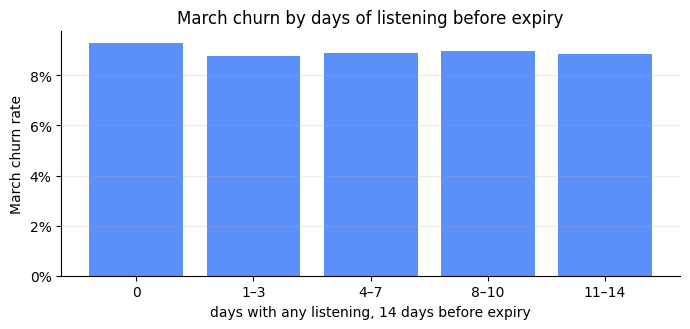

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.4))
g = mar.groupby(pd.cut(mar["days_active"], [-1, 0, 3, 7, 10, 14], labels=["0", "1–3", "4–7", "8–10", "11–14"]),
                observed=True)["is_churn"].mean()
ax.bar(g.index.astype(str), g.to_numpy(), color="#5B8FF9")
ax.set(xlabel="days with any listening, 14 days before expiry", ylabel="March churn rate",
       title="March churn by days of listening before expiry")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(alpha=0.25, axis="y")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
records.save_figure(fig, "03_kkbox_listening.png", SOURCE)

**How to read the figure.** Each bar is March churn for members who listened on that many of the 14 days before their expiry. The bars are close to flat: members who barely listened churn at about the same rate as daily listeners, which is why listening adds so little to the model.

**Tracked in MLflow.** Both models are logged as runs in the same experiment as notebook 02,
with their parameters and their scores on half B, so the comparison sits next to the model
selection runs.

In [5]:
from src.models.tracking import log_run

for name, feats in (("payments only", "payments"), ("payments + listening", "payments+listening")):
    log_run(f"kkbox_churn_{SOURCE}", f"listening_{feats}", params={"model": "lightgbm", "features": feats, **params},
            metrics={f"halfB_{k}": v for k, v in res.loc[name].items()},
            tags={"data": SOURCE, "stage": "listening check", "test": "March 2017, half B"})

In [6]:
record = {"logs_available": has_logs, "share_listening": float((mar["days_active"] > 0).mean()),
          "churn_by_days_active": {str(k): float(v) for k, v in g.items()},
          "half_b": res.to_dict(orient="index"), "listening_minus_payments": boot}
print("wrote", records.write("03_kkbox_listening", record, SOURCE).name)
print(f"Within March, listening before expiry moves PR-AUC from {res.iloc[0]['pr_auc']:.3f} to {res.iloc[1]['pr_auc']:.3f} "
      f"({boot['diff']:+.3f}, 95% CI {boot['ci'][0]:+.3f} to {boot['ci'][1]:+.3f}).")

wrote 03_kkbox_listening.json
Within March, listening before expiry moves PR-AUC from 0.719 to 0.730 (+0.011, 95% CI +0.010 to +0.012).


## Takeaways

- **Listening adds +0.011 PR-AUC**, real but small; payments are the signal.
- The numbers here are within March (a random half for training, the other for testing), so they are higher than notebook 02's out-of-time results and should not be compared directly.

**Next:** [notebook 04](04_kkbox_lifetime_value.ipynb), what a member is worth.